### Dylan Renard
### Applied Machine Learning JHU
### Homework 3
### Professor Alhassan
### Feb 6th, 2026


## HW Assignment 3: Applied Machine Learning @JHU

#### Q1. [10 pts] Due to the severity of this  real-world  crisis, what information  would be the most important  to "machine  learn"?  Can it be learned?  (Note that  this is asking  you to define the big-picture  question  that we want to answer  from this dataset.  This is not asking  you to conjecture which feature is going  to turn out being  important.) 

The most important information to “machine learn” from this dataset is whether population-level demographic and contextual factors can be used to distinguish relatively high suicide-rate situations from lower ones. Because the data are aggregated by country, year, sex, and age group, the appropriate learning objective is not individual prediction, but rather identifying which population contexts tend to be associated with elevated suicide rates. Framed this way, the dataset can support a meaningful classification task that helps highlight patterns across regions and demographic groups, which is valuable for public-health monitoring and hypothesis generation.

This information can be learned in a limited but useful sense. A machine learning model can capture statistical associations and predictive signals that separate higher-rate from lower-rate cases within the dataset. However, these learned patterns should not be interpreted as causal relationships or individual-level risk predictions. Important contributors to suicide, such as personal mental health history or access to care, are not present in the data, so the model’s role is best understood as identifying population-level trends rather than explaining underlying causes.


#### Q2. [10 pts] Explain  in detail  how one should  set up the problem. Would  it be a regression  or a classification  problem?  Is any unsupervised  approach,  to look for patterns,  worthwhile? 

From a supervised learning perspective, this dataset supports a regression based prediction task where the objective is to model the continuous outcome suicides/100k pop using demographic and socioeconomic features. Such a formulation could help estimate population level suicide risk based on prevailing public health conditions rather than individual level prediction. Relevant features include country, year, sex, age group, generation, population size, GDP per capita, and human development index, all of which provide contextual information that may influence suicide rates. As discussed in Chapter 1 of the course textbook, supervised learning is suitable when labeled outcomes are available and the goal is to model relationships between input variables and a continuous target (Raschka, 2022).

At the same time, care must be taken in interpreting population level suicide rates. Countries with very different population sizes may exhibit similar rates despite large differences in absolute counts, or vice versa. Although normalization per 100k population addresses this in part, additional context from population size may still be informative. Because of this, along with potential reporting differences, cultural variation, and economic disparities across countries, an unsupervised exploratory approach is particularly valuable. Clustering methods can help reveal whether countries or demographic groups naturally group together based on shared socioeconomic characteristics, providing insight into data structure and potential sources of bias before considering supervised predictive models for real world public health use (Raschka, 2022).

#### Q3. [20 pts] What  should  be the dependent  variable?
The dependent variable should be the continuous suicide rate per 100,000 population (suicides/100k pop). This variable provides a normalized measure of suicide incidence that allows meaningful comparison across countries, years, and demographic groups with very different population sizes. Using the rate rather than raw suicide counts ensures that the outcome reflects relative risk at the population level, which is appropriate given the public health focus of the dataset.

Selecting a continuous dependent variable supports a regression based formulation that preserves the full variability in the data and avoids imposing arbitrary thresholds or categories. This choice is especially appropriate for exploratory and analytical goals, as it allows the model to capture gradual differences in suicide rates across contexts and supports downstream analyses such as pattern discovery, correlation analysis, and clustering. Because the data are aggregated and ecological in nature, the dependent variable should be interpreted strictly at the population level rather than as an individual level risk measure.

#### Q4. [20 pts] Find  some strong correlations  between  the independent  variables  and the dependent  variable  you decided  and use them to rank the independent  variables. 

C:\Users\drena\AppData\Local\Temp\ipykernel_22480\874505246.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include="object").columns.tolist()


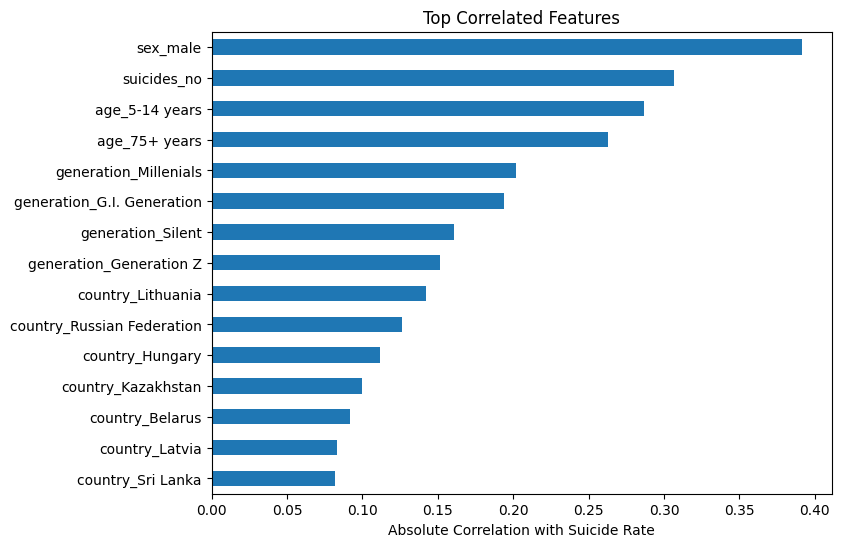

In [3]:
# %pip install matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("master.csv")

y = df["suicides/100k pop"]

numeric_features = df.select_dtypes(include=np.number).columns.tolist()
categorical_features = df.select_dtypes(include="object").columns.tolist()

# Remove dependent variable from numeric features
numeric_features.remove("suicides/100k pop")

numeric_corr = (
    df[numeric_features]
    .corrwith(y)
    .sort_values(key=np.abs, ascending=False)
)

numeric_corr

df_encoded = pd.get_dummies(
    df[categorical_features],
    drop_first=True
)

categorical_corr = (
    df_encoded
    .corrwith(y)
    .sort_values(key=np.abs, ascending=False)
)

categorical_corr.head(10)

all_corr = pd.concat([numeric_corr, categorical_corr])

feature_ranking = (
    all_corr
    .abs()
    .sort_values(ascending=False)
)

feature_ranking


feature_ranking.head(15).plot(kind="barh", figsize=(8,6))
plt.xlabel("Absolute Correlation with Suicide Rate")
plt.title("Top Correlated Features")
plt.gca().invert_yaxis()
plt.show()

Correlation analysis revealed that demographic variables such as sex and age group exhibit the strongest associations with suicide rate, followed by generational indicators and country specific effects. Socioeconomic and regional patterns appear in the country indicators, though these likely reflect contextual and reporting differences rather than causal effects. Variables directly tied to outcome magnitude were identified and treated cautiously to avoid leakage. Overall, this ranking provides a data driven basis for prioritizing features in subsequent exploratory and regression analyses.

#### Q5. [20 pts] Pre-process  the dataset  and list the major features  you want to use.  Note  that not all features  are crucial. For example, country-year variable  is a derived feature and for a classifier  it would  not be necessary  to include the year, the country and the country -year together.  In fact, one must avoid adding  a derived  feature and  the original  at the same time. List  the independent  features  you want to use. 

#### Q6. [20 pts] Devise a classification  problem and  present  a working prototype  model. (It does not have to perform great, but it has  to be functional.) Note that we will continue  with this  problem in the following modules. 

#### References:

Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.

Yeafi, A. (2024). Suicide Rates Overview 1985 to 2016 around globe. Kaggle. https://www.kaggle.com/code/ashfakyeafi/suicide-rates-overview-1985-to-2016-around-globe